# 01 - Data exploration and target definition

Data Mining 2026 project: predicting trademark registration failure in Israel.

This notebook checks the raw data, explains why the `status` column can't be the label,
defines the target, and looks at how the main features relate to failure.

In [1]:
### CODE BY CLAUDE ###
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from load_data import load_raw
from prepare import clean, build_dataset, LEAKAGE_COLUMNS, FIRST_YEAR, LAST_YEAR

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
####

## 1. Load and clean

In [2]:
### CODE BY CLAUDE ###
raw = load_raw()
df = clean(raw)
print(df.shape)
df.head(3)
####

Loaded 364,115 rows, dropped 123 malformed rows


(364115, 34)


,row_id,mark_number,is_figurative,link,status,route,intl_number,mark_text_he,mark_text_en,filing_date,registration_date,registration_type,nice_classes,vienna_codes,goods_he,goods_en,priority_claim,expiry_date,attorney_he,attorney_en,owner_he,owner_en,licensee_he,licensee_en,customs_rep,customs_start_date,customs_email,customs_phone,external_registration,last_update,,filing_year,is_decided,failed
0,1,9,לא,https://trademarks.justice.gov,registered,לאומי,NaN,NaN,KOH-I-NOOR,1920-12-24,1921-03-24,סימן מסחר/שירות,16,NaN,NaN,Pencils etc.,לא,2030-12-24,ריינהולד כהן ושותפיו,Reinhold Cohn and Partners,NaN,ETABLISSEMENT INTERNATIONAL CRAYOMINE,NaN,NaN,NaN,NaT,NaN,NaN,לא,2026-08-20,NaN,1920,True,0
1,2,11,לא,https://trademarks.justice.gov,registered,לאומי,NaN,NaN,KODAK,1924-06-19,1925-09-21,סימן מסחר/שירות,9; 1,NaN,כימיקלים פוטוגרפיים וכל שאר הסחורות הנכללות בס...,Photographic chemicals and all other goods inc...,לא,2034-06-19,ריינהולד כהן ושותפיו,Reinhold Cohn and Partners,NaN,Eastman Kodak Company,NaN,NaN,NaN,NaT,NaN,NaN,לא,2026-08-20,NaN,1924,True,0
2,3,16,לא,https://trademarks.justice.gov,closed,לאומי,NaN,NaN,SANITAS,1922-08-13,1925-10-09,סימן מסחר/שירות,3,NaN,דאודורנטים~ חומרי חיטוי~ וחומרים אנטיספטיים.,Deodorants~ disinfectants and antisepties.,לא,2000-06-18,"וולף, ברגמן וגולר","Wolff, Bregman and Goller",NaN,BEECHAM GROUP P.L.C. (A.T.A. J.C. ENO & CO.),NaN,NaN,NaN,NaT,NaN,NaN,לא,2021-07-21,NaN,1922,True,0


## 2. Overview: types, missing values, unique values

In [3]:
### CODE BY CLAUDE ###
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_%": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
}).sort_values("missing_%")
overview
####

,dtype,missing_%,n_unique
row_id,str,0.0,364115
mark_number,str,0.0,364115
is_figurative,str,0.0,2
link,str,0.0,1
status,str,0.0,9
route,str,0.0,3
registration_type,str,0.0,4
filing_date,datetime64[us],0.0,21147
nice_classes,str,0.0,10954
filing_year,int32,0.0,107


Several columns are almost empty (licensee, customs representative) and won't be useful.
`link` has a single value. The Hebrew mark text and Hebrew owner name are missing in most rows,
the English versions are much more complete.

## 3. Status vs. registration date: why status is not the label

In [4]:
### CODE BY CLAUDE ###
status_reg = pd.crosstab(df["status"], df["registration_date"].notna().rename("has_registration_date"))
status_reg
####

has_registration_date,False,True
status,,
awaiting_exam,2428,0
awaiting_other_case,13,0
closed,54712,141354
first_exam,87,0
non_payment,0,1857
opposed,2333,0
registered,3,158708
second_exam,2603,0
sorting,17,0


Most `closed` applications have a registration date: they were registered and later lapsed.
All `non_payment` rows are registered marks whose renewal wasn't paid.
So using `closed` as "failed" would mix real failures with expired registrations.

**Target:** `failed = 1` if the application was decided (registered / closed / non_payment)
and has no registration date. Applications still in process (exams, opposition) are removed.

Pending applications (no outcome yet): 7481
Failure rate among all decided applications: 0.1534


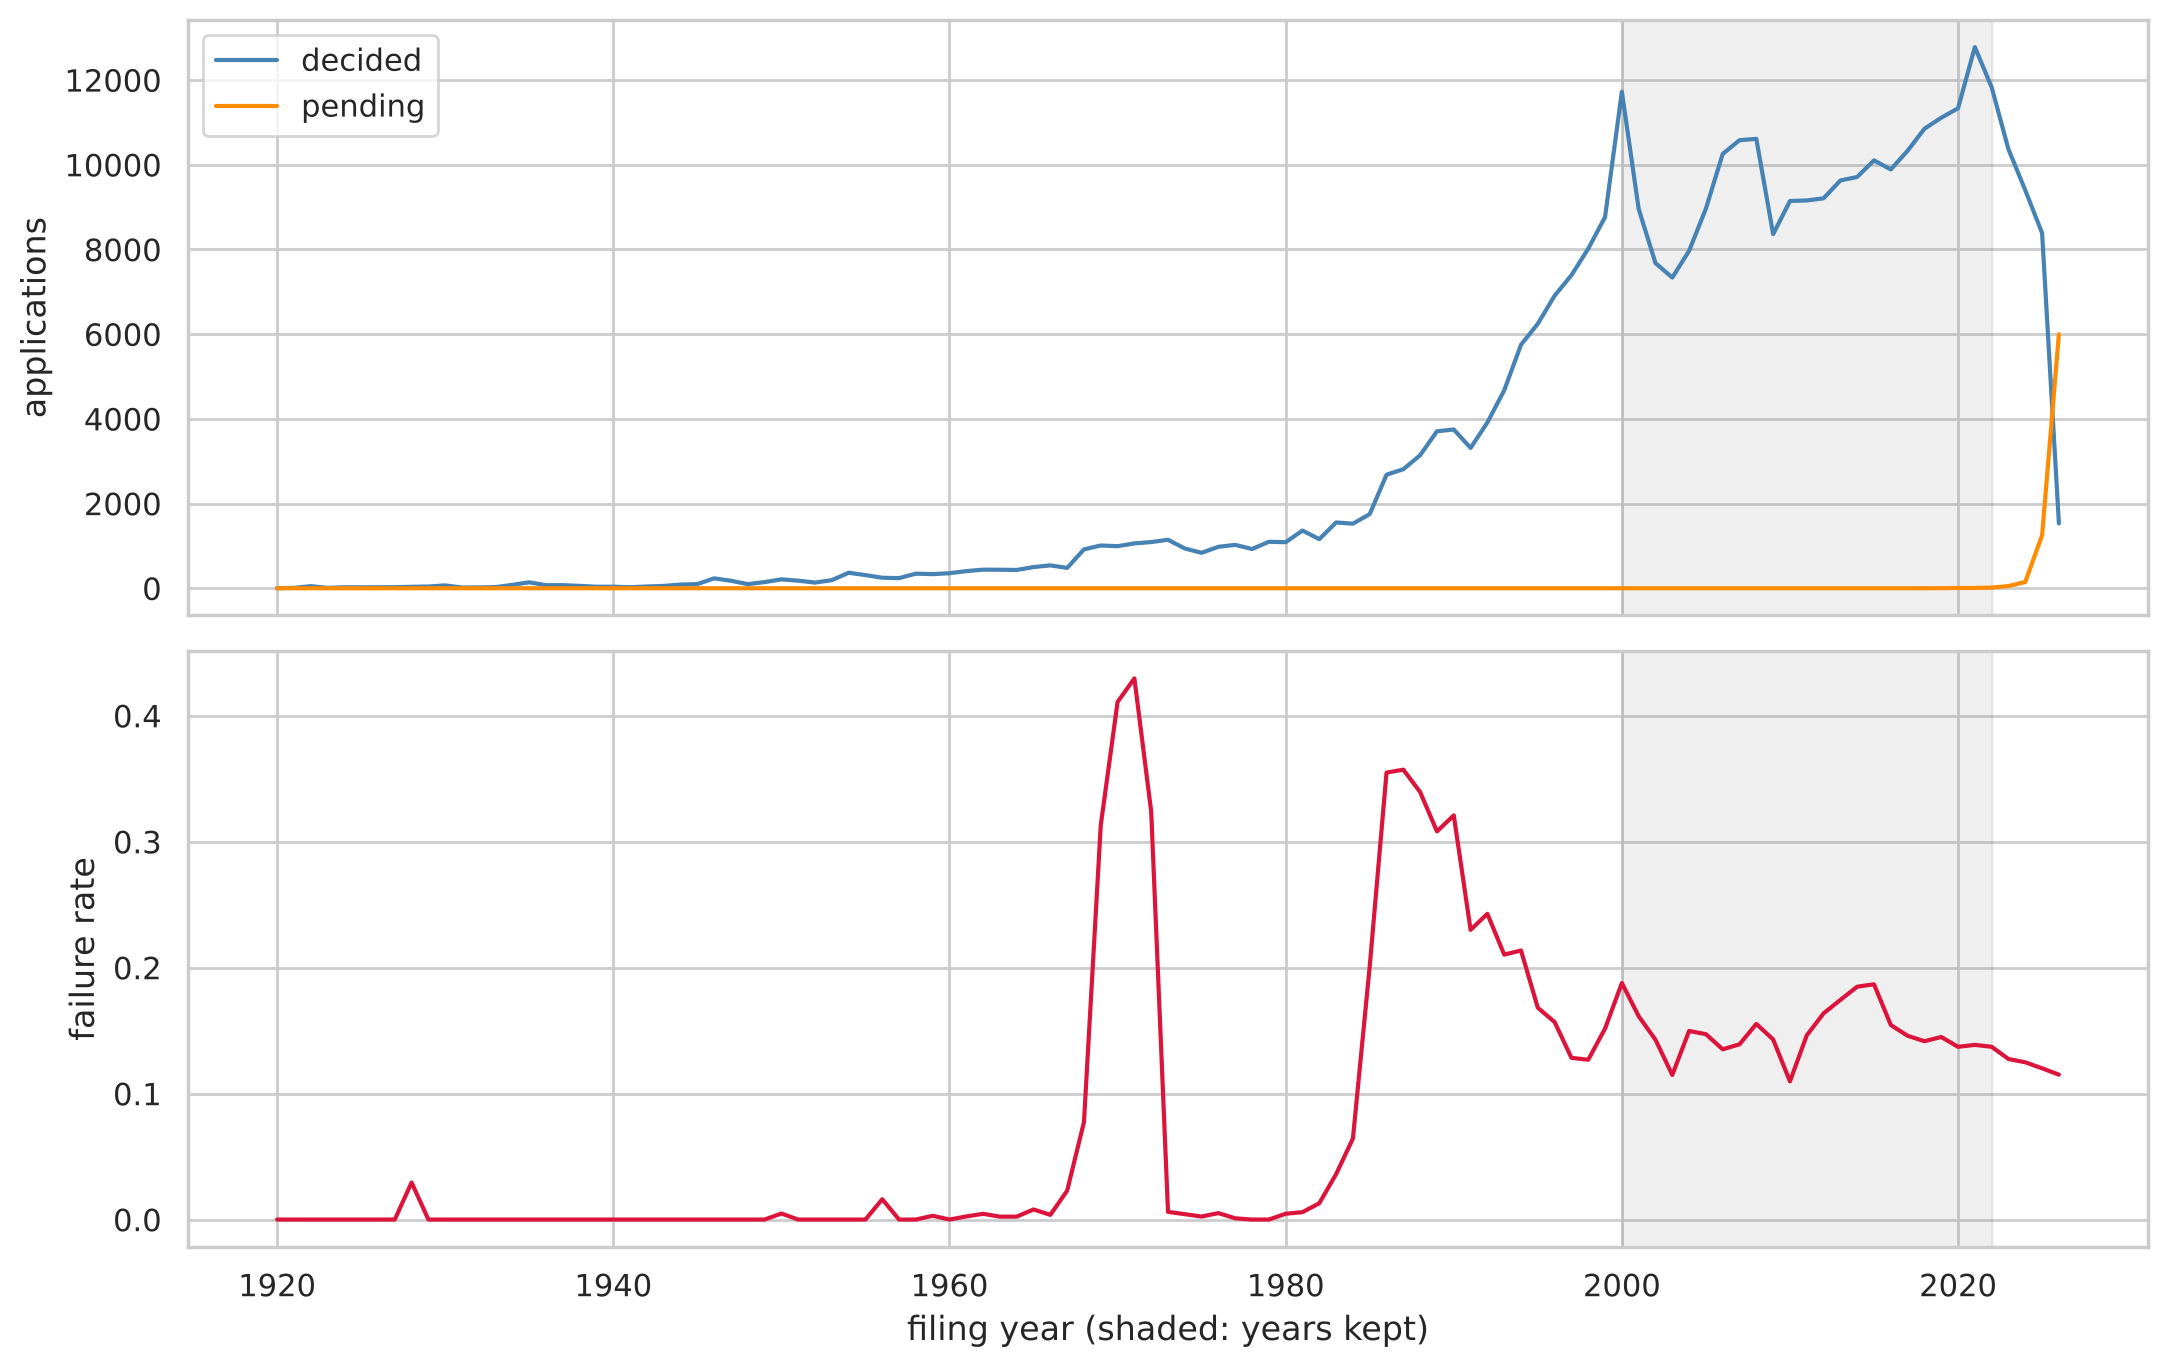

In [5]:
### CODE BY CLAUDE ###
print("Pending applications (no outcome yet):", (~df["is_decided"]).sum())
print("Failure rate among all decided applications:", round(df.loc[df["is_decided"], "failed"].mean(), 4))

per_year = (df[df["is_decided"]].groupby("filing_year")
            .agg(n=("failed", "size"), failure_rate=("failed", "mean")))
pending_year = df[~df["is_decided"]].groupby("filing_year").size().rename("pending")
per_year = per_year.join(pending_year).fillna({"pending": 0})

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
per_year["n"].plot(ax=axes[0], color="steelblue")
per_year["pending"].plot(ax=axes[0], color="darkorange")
axes[0].set_ylabel("applications")
axes[0].legend(["decided", "pending"])
per_year["failure_rate"].plot(ax=axes[1], color="crimson")
axes[1].set_ylabel("failure rate")
for ax in axes:
    ax.axvspan(FIRST_YEAR, LAST_YEAR, color="grey", alpha=0.12)
axes[1].set_xlabel("filing year (shaded: years kept)")
plt.tight_layout()
plt.savefig(FIG / "applications_and_failure_by_year.png", dpi=120)
plt.show()
####

Before 2000 there are fewer applications and the failure rate jumps in ways that look like changes in record keeping
(spikes around 1970 and 1985-1990, and almost no failures before that).
From 2023 many applications are still pending, so their outcome isn't known yet
(keeping them would bias the failure rate down). We keep 2000-2022.

In [6]:
### CODE BY CLAUDE ###
data = build_dataset(df)
print("Rows kept:", len(data))
print("Failure rate:", round(data["failed"].mean(), 4))
data["failed"].value_counts()
####

Rows kept: 227489
Failure rate: 0.1501


failed
0    193353
1     34136
Name: count, dtype: int64

## 4. Time-based train / test split

In [7]:
### CODE BY CLAUDE ###
split = data["filing_year"].le(2018).map({True: "train (2000-2018)", False: "test (2019-2022)"})
data.groupby(split)["failed"].agg(n="size", failure_rate="mean").round(4)
####

,n,failure_rate
filing_year,,
test (2019-2022),47047,0.1394
train (2000-2018),180442,0.1528


The failure rate is fairly stable between the two periods (about 15% vs 14%),
so the test period isn't very different in class balance. The classes are imbalanced in both.

## 5. Categorical features vs. failure (Lift and chi-square)

Lift = P(failed | category) / P(failed). Lift > 1 means the category fails more than average.
With over 200K rows almost any relation is significant, so we also report Cramér's V
for the size of the effect.

In [8]:
### CODE BY CLAUDE ###
base_rate = data["failed"].mean()

def lift_table(col):
    t = data.groupby(col, dropna=False)["failed"].agg(n="size", failure_rate="mean")
    t["lift"] = t["failure_rate"] / base_rate
    return t.sort_values("n", ascending=False).round(3)

def chi_square(col):
    ct = pd.crosstab(data[col].fillna("missing"), data["failed"])
    chi2, p, dof, _ = chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return {"feature": col, "chi2": round(chi2, 1), "p_value": p, "cramers_v": round(cramers_v, 3)}

data["has_attorney"] = data["attorney_en"].notna() | data["attorney_he"].notna()
data["has_vienna"] = data["vienna_codes"].notna()
data["has_owner_he"] = data["owner_he"].notna()

cat_cols = ["route", "is_figurative", "priority_claim", "registration_type",
            "has_attorney", "has_vienna", "has_owner_he"]
pd.DataFrame([chi_square(c) for c in cat_cols]).sort_values("cramers_v", ascending=False)
####

,feature,chi2,p_value,cramers_v
6,has_owner_he,8107.1,0.000000e+00,0.189
5,has_vienna,1949.3,0.000000e+00,0.093
0,route,844.4,4.438126e-184,0.061
1,is_figurative,557.7,2.660736e-123,0.050
4,has_attorney,495.1,1.116915e-109,0.047
2,priority_claim,449.1,1.120515e-99,0.044
3,registration_type,167.7,4.064015e-36,0.027


In [9]:
### CODE BY CLAUDE ###
for col in ["route", "priority_claim", "is_figurative", "has_attorney", "has_owner_he"]:
    display(lift_table(col))
####

,n,failure_rate,lift
route,,,
לאומי,155443,0.163,1.087
בינלאומי,68432,0.126,0.839
בסיס לבינלאומי,3614,0.044,0.291


,n,failure_rate,lift
priority_claim,,,
לא,165268,0.160,1.065
כן,62221,0.124,0.828


,n,failure_rate,lift
is_figurative,,,
כן,139959,0.136,0.907
לא,87530,0.172,1.149


,n,failure_rate,lift
has_attorney,,,
True,169367,0.140,0.935
False,58122,0.179,1.190


,n,failure_rate,lift
has_owner_he,,,
False,165808,0.109,0.726
True,61681,0.261,1.737


- Applications filed through the international route, with a priority claim, with a figurative element or with an attorney fail less.
- `has_owner_he` (a Hebrew owner name, a rough proxy for a local applicant) has the strongest effect: 26% failure vs 11%.
  It's present in national filings only. We need to check it isn't filled in during examination (that would be leakage)
  before using it as a feature.
- All Cramér's V values are small (below 0.2), so no single feature separates the classes on its own.

## 6. Nice classes

In [10]:
### CODE BY CLAUDE ###
classes = data["nice_classes"].fillna("").str.split(";").apply(
    lambda xs: [int(x) for x in (s.strip() for s in xs) if x.isdigit()])
data["n_classes"] = classes.str.len()

print(data["n_classes"].describe())
n_cls = data.groupby(data["n_classes"].clip(upper=6))["failed"].agg(n="size", failure_rate="mean")
n_cls.index = [str(i) if i < 6 else "6+" for i in n_cls.index]
n_cls.round(3)
####

count    227489.000000
mean          1.543195
std           1.556800
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          45.000000
Name: n_classes, dtype: float64


,n,failure_rate
0,26,1.000
1,174845,0.159
2,24452,0.130
3,13862,0.120
4,5877,0.111
5,3168,0.092
6+,5259,0.087


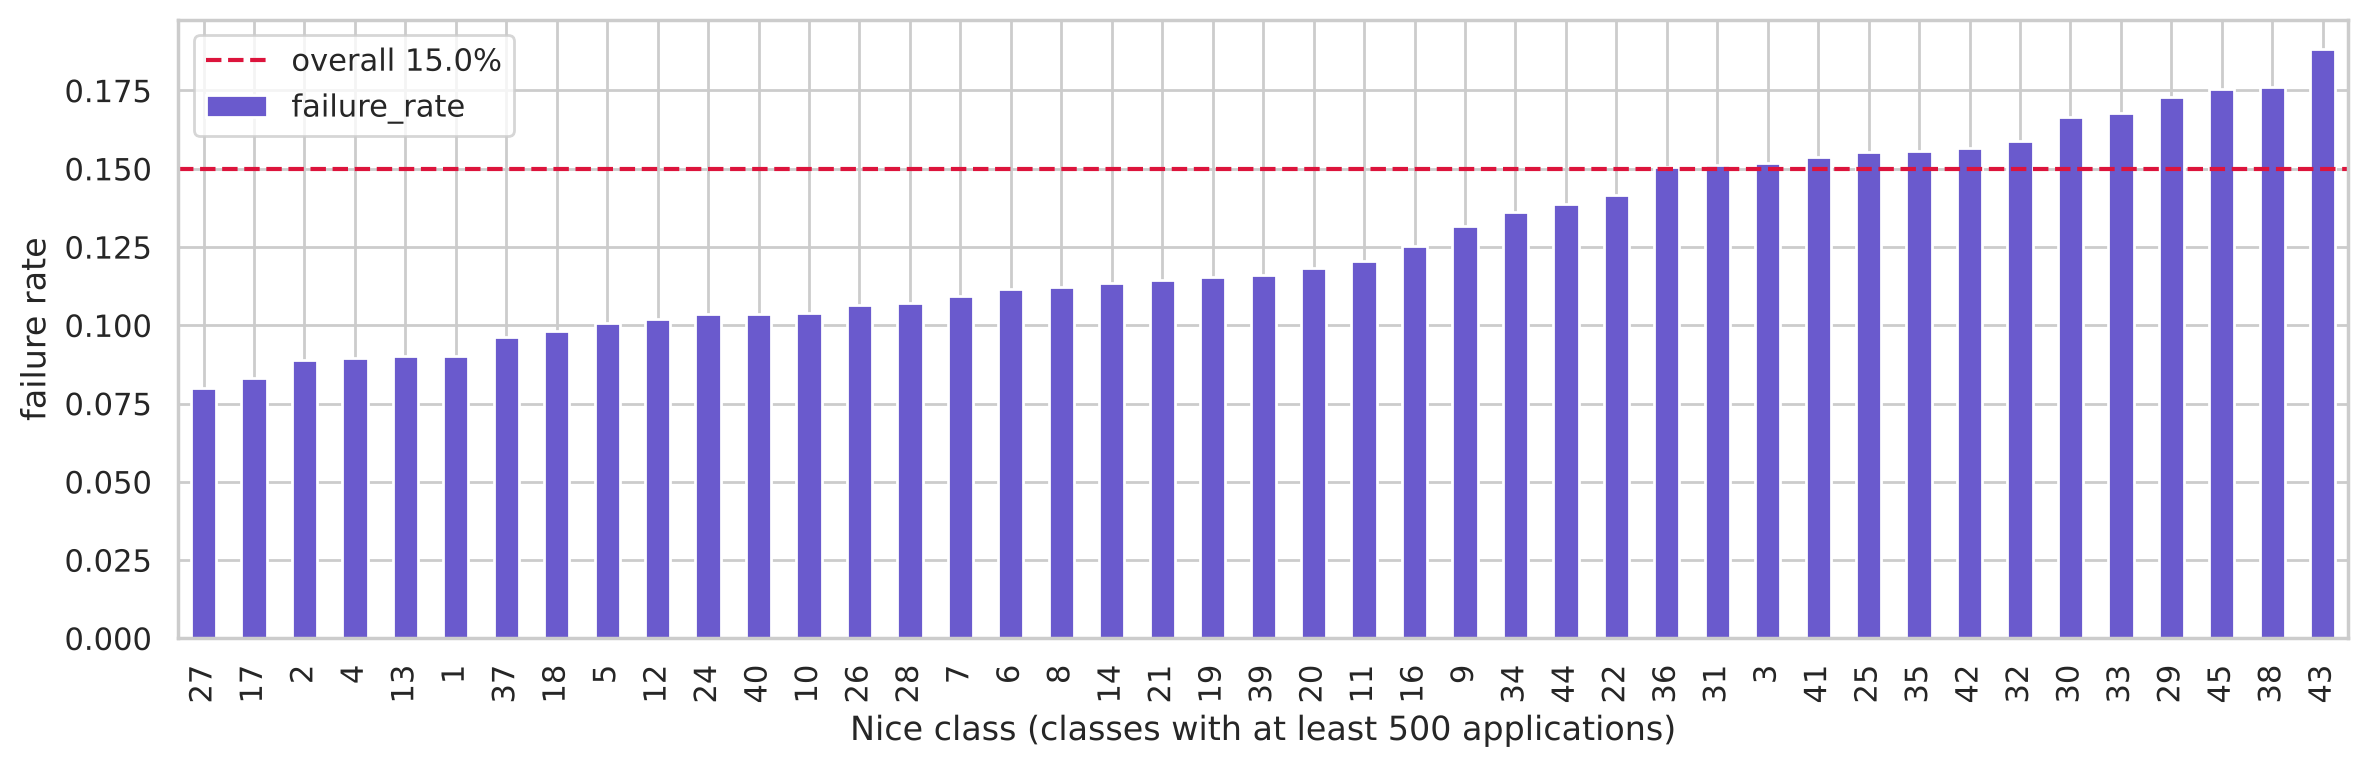

In [11]:
### CODE BY CLAUDE ###
exploded = pd.DataFrame({"nice_class": classes, "failed": data["failed"]}).explode("nice_class").dropna()
by_class = exploded.groupby("nice_class")["failed"].agg(n="size", failure_rate="mean")
by_class = by_class[by_class["n"] >= 500].sort_values("failure_rate")

fig, ax = plt.subplots(figsize=(12, 4))
by_class["failure_rate"].plot.bar(ax=ax, color="slateblue")
ax.axhline(base_rate, color="crimson", ls="--", label=f"overall {base_rate:.1%}")
ax.set_xlabel("Nice class (classes with at least 500 applications)")
ax.set_ylabel("failure rate")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "failure_rate_by_nice_class.png", dpi=120)
plt.show()
####

Failure drops as the number of classes grows. The 26 applications with no valid class all failed; we will check them separately.

## 7. Text fields

,n,failure_rate,lift
mark_script,,,
latin,181928,0.136,0.909
hebrew,16790,0.239,1.590
both,13908,0.279,1.862
none,13013,0.094,0.623
other,1850,0.110,0.735


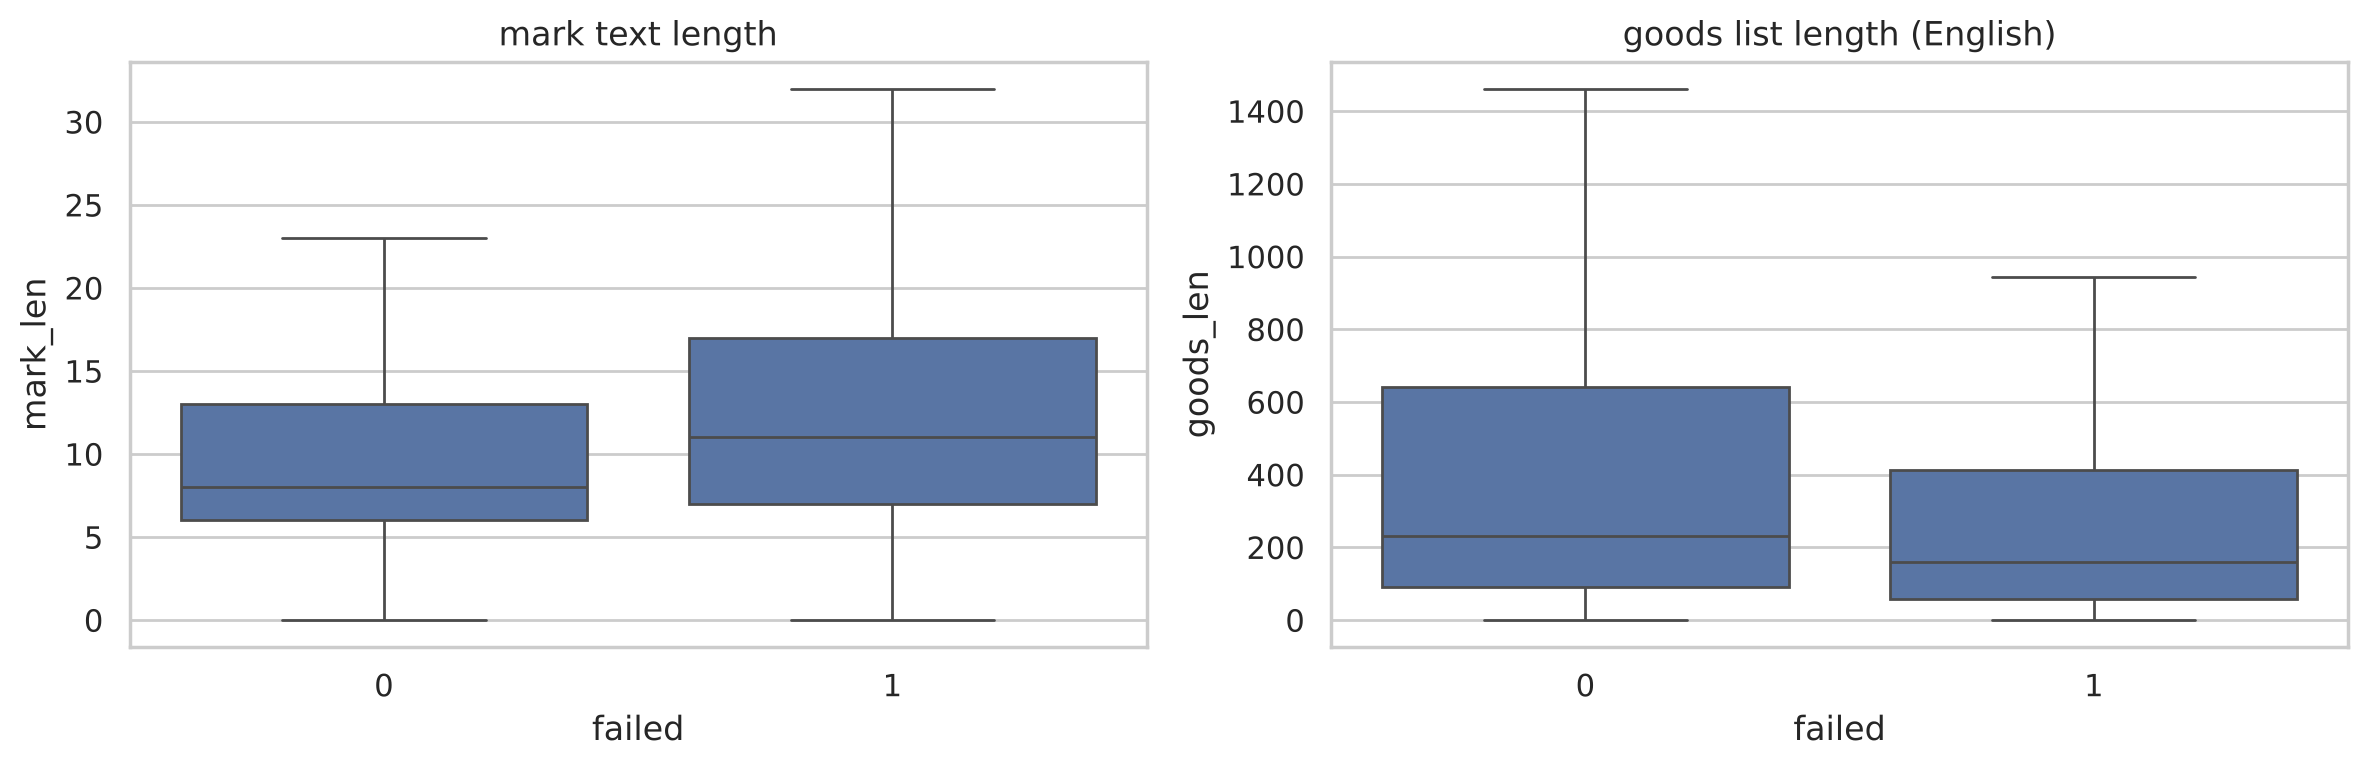

In [12]:
### CODE BY CLAUDE ###
def script(text):
    if pd.isna(text):
        return "none"
    has_he = any("\u0590" <= ch <= "\u05FF" for ch in text)
    has_latin = any(ch.isascii() and ch.isalpha() for ch in text)
    return {(True, True): "both", (True, False): "hebrew", (False, True): "latin"}.get((has_he, has_latin), "other")

mark_text = data["mark_text_en"].fillna("") + " " + data["mark_text_he"].fillna("")
mark_text = mark_text.str.strip().replace("", pd.NA)
data["mark_script"] = mark_text.apply(script)
data["mark_len"] = mark_text.str.len().fillna(0)
data["goods_len"] = data["goods_en"].fillna("").str.len()

display(lift_table("mark_script"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=data, x="failed", y="mark_len", ax=axes[0], showfliers=False)
sns.boxplot(data=data, x="failed", y="goods_len", ax=axes[1], showfliers=False)
axes[0].set_title("mark text length")
axes[1].set_title("goods list length (English)")
plt.tight_layout()
plt.savefig(FIG / "text_length_vs_failure.png", dpi=120)
plt.show()
####

Marks written in Hebrew (or Hebrew + Latin) fail much more often (24-28%) than Latin-only marks (14%).
Marks with no text at all (figurative only) fail the least.

## 8. Owners and attorneys

In [13]:
### CODE BY CLAUDE ###
owner = data["owner_en"].fillna(data["owner_he"])
attorney = data["attorney_en"].fillna(data["attorney_he"])
print("Unique owners:", owner.nunique(), "| unique attorneys:", attorney.nunique())
print("Applications without attorney:", round(attorney.isna().mean(), 3))

top_att = attorney.value_counts().head(15).index
att = data.assign(attorney=attorney)[attorney.isin(top_att)]
att.groupby("attorney")["failed"].agg(n="size", failure_rate="mean").sort_values("n", ascending=False).round(3)
####

Unique owners: 71800 | unique attorneys: 5695
Applications without attorney: 0.255


,n,failure_rate
attorney,,
Reinhold Cohn and Partners,33570,0.071
Dr. Shlomo Cohen & Co.,13868,0.105
Sanford T. Colb & Co.,9494,0.129
"Wolff, Bregman and Goller",7146,0.109
Seligsohn Gabrieli & Co.,6265,0.104
Pearl Cohen Zedek Latzer Baratz,5919,0.083
Luzzatto & Luzzatto,5228,0.107
Gornitsky & Co.,3940,0.091
"Soroker Nordman Riba, Adv. & Patent Attorneys:",3720,0.130


The big firms fail less than average (7-13%), while applications with no attorney fail at 17.9%.
So attorney identity and experience look useful.
It has to be computed only from applications filed **before** each application
(and only from training data), otherwise it leaks the label.

## 9. Summary

In [14]:
### CODE BY CLAUDE ###
print("Columns never used as features (leakage):", LEAKAGE_COLUMNS)
print(f"Final dataset: {len(data):,} applications, {data['failed'].mean():.1%} failed")
####

Columns never used as features (leakage): ['status', 'registration_date', 'expiry_date', 'last_update']
Final dataset: 227,489 applications, 15.0% failed


Main points:

1. `status` is misleading as a label. The target is "decided with no registration date".
2. We keep decided applications filed 2000-2022; about 15% failed (imbalanced).
3. The time split gives similar failure rates in train and test.
4. Route, priority claim, figurative marks, attorney, Nice classes and the mark's script all relate to failure, each with a small effect.
5. Next step: feature engineering (history features, TF-IDF on goods) in notebook 02.